# Análise Estatística Completa — Benchmark de LLMs para geração de SMILES
**Autor:** Lucas Abner

Este notebook consolida as duas rodadas experimentais (Task 1 e Task 2) em um único arquivo, mantendo o mesmo pipeline estatístico entre ambas para permitir comparação direta.

- **TASK 1** — Rodada com `total_smiles` fixo em 20 por réplica.
- **TASK 2** — Rodada com `total_smiles` variável (0 a 39 por réplica), incluindo análises adicionais (taxa de falha, GLM Quasi-Binomial com interação).


# TASK 1

**Objetivo:** Avaliar o impacto do modelo e da quantização na validade dos SMILES gerados, no tempo de resposta e na velocidade (tokens/s) das LLMs testadas.

## Estrutura
- Seção 0 — Setup e carregamento
- Estatística descritiva (geral + por modelo)
- Seção 1.1 — Normalidade (Shapiro-Wilk) e Homocedasticidade (Levene)
- Seção 1.2 — Qui-quadrado de Independência (efeito modelo) + visualização
- Seção 1.3 — Kruskal-Wallis + Dunn's (efeito modelo)
- Seção 1.4 — Efeito da Quantização (1.4a Teste Z / 1.4b Kruskal global / 1.4c Kruskal por modelo)
- Seção 1.5 — ANOVA tokens/s + Friedman + correlações
- Heatmap — Modelo × Quantização
- Seção 1.6 — Torneio dos Campeões


## Seção 0 — Setup

In [1]:
!pip install scikit-posthocs -q

In [7]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from itertools import combinations
from scipy import stats
from scipy.stats import shapiro, levene, kruskal, spearmanr, pointbiserialr
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.proportion import proportions_ztest

import scikit_posthocs as sp
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 200)

# Carregar dados
df = pd.read_csv("./results/task_1/results_per_replica.csv")

# Remover Mistral3.2-24B (excluído do escopo)
df = df[~df['modelo'].str.contains('Mistral3.2-24B', case=False)].copy()

# Colunas auxiliares
df['total_smiles_invalidos'] = df['total_smiles'] - df['total_smiles_validos']
df['taxa_validos'] = df['total_smiles_validos'] / df['total_smiles']
df['grupo'] = df['modelo'] + "_" + df['quantizacao']

print(f"Total de réplicas: {len(df)}")
print(f"Modelos: {sorted(df['modelo'].unique())}")
print(f"Quantizações: {sorted(df['quantizacao'].unique())}")
print("\nN por combinação modelo × quantização:")
print(df.groupby(['modelo','quantizacao']).size().unstack(fill_value=0))
df.head()

Total de réplicas: 387
Modelos: ['Mistral4-119B', 'Qwen3.6-35B', 'gemma-4-31B', 'gpt-oss-120B']
Quantizações: ['BF16', 'Q4', 'Q6', 'Q8']

N por combinação modelo × quantização:
quantizacao    BF16  Q4  Q6  Q8
modelo                         
Mistral4-119B    22  21  21  23
Qwen3.6-35B      25  25  25  25
gemma-4-31B      25  25  25  25
gpt-oss-120B     25  25  25  25


,task,modelo,quantizacao,replica,total_smiles,total_smiles_validos,total_smiles_duplicados,pct_validos,pct_invalidos,duration_min_media,token_per_second_medio,total_smiles_invalidos,taxa_validos,grupo
0,task_1,Mistral4-119B,BF16,Mistral4-119B-BF16_replica_1,20,19,0,95.00000,5.00000,13.764699,4.43333,1,0.950000,Mistral4-119B_BF16
1,task_1,Mistral4-119B,BF16,Mistral4-119B-BF16_replica_10,20,20,0,100.00000,0.00000,13.764699,4.43333,0,1.000000,Mistral4-119B_BF16
2,task_1,Mistral4-119B,BF16,Mistral4-119B-BF16_replica_11,20,17,0,85.00000,15.00000,13.764699,4.43333,3,0.850000,Mistral4-119B_BF16
3,task_1,Mistral4-119B,BF16,Mistral4-119B-BF16_replica_12,21,19,0,90.47619,9.52381,13.764699,4.43333,2,0.904762,Mistral4-119B_BF16
4,task_1,Mistral4-119B,BF16,Mistral4-119B-BF16_replica_13,20,16,0,80.00000,20.00000,13.764699,4.43333,4,0.800000,Mistral4-119B_BF16


## Estatística descritiva geral (modelo × quantização)

In [8]:
desc = df.groupby(['modelo','quantizacao'])['taxa_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)
desc['CV(%)'] = (desc['desvio_padrao'] / desc['media'] * 100).round(2)
desc

n   media  mediana  desvio_padrao     IQR  minimo  maximo  CV(%)
modelo        quantizacao                                                                   
Mistral4-119B BF16         22  0.8644   0.8461         0.0882  0.1493  0.7000     1.0  10.20
              Q4           21  0.7109   0.7895         0.2886  0.2569  0.0000     1.0  40.60
              Q6           21  0.8710   0.8947         0.1009  0.1722  0.7000     1.0  11.58
              Q8           23  0.8797   0.9000         0.1498  0.1699  0.4500     1.0  17.03
Qwen3.6-35B   BF16         25  0.9607   1.0000         0.0538  0.0500  0.8182     1.0   5.60
              Q4           25  0.9385   1.0000         0.0993  0.1000  0.5625     1.0  10.58
              Q6           25  0.9780   1.0000         0.0356  0.0500  0.9000     1.0   3.64
              Q8           25  0.9480   0.9500         0.0603  0.1000  0.8000     1.0   6.36
gemma-4-31B   BF16         25  0.8920   0.9000         0.1028  0.1000  0.5000     1.0  11.52
              Q4           25  0.9280   0.9500         0.1011  0.1000  0.6000     1.0  10.89
              Q6           25  0.9040   0.9000         0.0660  0.1000  0.8000     1.0   7.30
              Q8           25  0.8920   0.9500         0.1028  0.1000  0.6500     1.0  11.52
gpt-oss-120B  BF16         25  0.9360   0.9500         0.0654  0.1000  0.7500     1.0   6.99
              Q4           25  0.9740   1.0000         0.0293  0.0500  0.9000     1.0   3.01
              Q6           25  0.9600   0.9500         0.0456  0.0500  0.8500     1.0   4.75
              Q8           25  0.9280   0.9500         0.0843  0.1000  0.6500     1.0   9.08

## Estatística descritiva individual por modelo

In [9]:
# --- gemma-4-31B ---
sub = df[df['modelo'] == 'gemma-4-31B']
print("Estatística descritiva — gemma-4-31B")
sub.groupby('quantizacao')['total_smiles_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)

Estatística descritiva — gemma-4-31B


,n,media,mediana,desvio_padrao,IQR,minimo,maximo
quantizacao,,,,,,,
BF16,25,17.84,18.0,2.0551,2.0,10,20
Q4,25,18.56,19.0,2.0224,2.0,12,20
Q6,25,18.08,18.0,1.3204,2.0,16,20
Q8,25,17.84,19.0,2.0551,2.0,13,20


In [10]:
# --- Qwen3.6-35B ---
sub = df[df['modelo'] == 'Qwen3.6-35B']
print("Estatística descritiva — Qwen3.6-35B")
sub.groupby('quantizacao')['total_smiles_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)

Estatística descritiva — Qwen3.6-35B


,n,media,mediana,desvio_padrao,IQR,minimo,maximo
quantizacao,,,,,,,
BF16,25,19.28,20.0,0.9363,1.0,17,20
Q4,25,18.68,20.0,2.3580,2.0,9,20
Q6,25,19.56,20.0,0.7118,1.0,18,20
Q8,25,18.96,19.0,1.2069,2.0,16,20


In [11]:
# --- gpt-oss-120B ---
sub = df[df['modelo'] == 'gpt-oss-120B']
print("Estatística descritiva — gpt-oss-120B")
sub.groupby('quantizacao')['total_smiles_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)

Estatística descritiva — gpt-oss-120B


,n,media,mediana,desvio_padrao,IQR,minimo,maximo
quantizacao,,,,,,,
BF16,25,18.72,19.0,1.3077,2.0,15,20
Q4,25,19.48,20.0,0.5859,1.0,18,20
Q6,25,19.20,19.0,0.9129,1.0,17,20
Q8,25,18.56,19.0,1.6852,2.0,13,20


In [12]:
# --- Mistral4-119B ---
sub = df[df['modelo'] == 'Mistral4-119B']
print("Estatística descritiva — Mistral4-119B")
sub.groupby('quantizacao')['total_smiles_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)

Estatística descritiva — Mistral4-119B


,n,media,mediana,desvio_padrao,IQR,minimo,maximo
quantizacao,,,,,,,
BF16,22,16.8636,16.5,2.0770,3.0,12,20
Q4,21,13.0000,18.0,8.0436,18.0,0,20
Q6,21,17.2857,18.0,2.0529,4.0,14,20
Q8,23,16.6087,18.0,4.5200,3.0,1,20


## Seção 1.1 — Normalidade (Shapiro-Wilk) e Homocedasticidade (Levene)

**Shapiro-Wilk:** testa se cada grupo segue distribuição normal.  
- H0: dados normais. p < 0,05 → não-normal.

**Levene (Brown-Forsythe, centro na mediana):** testa se as variâncias são iguais entre grupos.  
- H0: variâncias iguais. p < 0,05 → heterocedástico.

Se qualquer um falhar → justifica testes não-paramétricos (Kruskal-Wallis, Dunn's).

In [14]:
# Shapiro-Wilk por grupo
sw_results = []
for grupo, sub in df.groupby('grupo'):
    if len(sub) >= 3:
        W, p = shapiro(sub['taxa_validos'])
        sw_results.append({'grupo': grupo, 'n': len(sub),
                           'W': round(W, 4), 'p': p,
                           'Normal?': 'Sim' if p > 0.05 else 'Não'})
sw_df = pd.DataFrame(sw_results).sort_values('p')
print("Shapiro-Wilk por grupo (modelo_quantizacao):")
print(sw_df.to_string(index=False))
print(f"\nGrupos não-normais: {(sw_df['Normal?']=='Não').sum()} de {len(sw_df)}")

Shapiro-Wilk por grupo (modelo_quantizacao):
             grupo  n      W        p Normal?
    Qwen3.6-35B_Q6 25 0.6445 0.000001     Não
    Qwen3.6-35B_Q4 25 0.6654 0.000003     Não
   gpt-oss-120B_Q4 25 0.7214 0.000014     Não
    gemma-4-31B_Q4 25 0.7229 0.000015     Não
  Qwen3.6-35B_BF16 25 0.7509 0.000038     Não
  gemma-4-31B_BF16 25 0.7661 0.000065     Não
   gpt-oss-120B_Q6 25 0.7988 0.000217     Não
   gpt-oss-120B_Q8 25 0.8005 0.000231     Não
  Mistral4-119B_Q8 23 0.7932 0.000298     Não
    Qwen3.6-35B_Q8 25 0.8119 0.000362     Não
 gpt-oss-120B_BF16 25 0.8404 0.001165     Não
  Mistral4-119B_Q4 21 0.8162 0.001175     Não
    gemma-4-31B_Q8 25 0.8628 0.003114     Não
    gemma-4-31B_Q6 25 0.9073 0.026577     Não
  Mistral4-119B_Q6 21 0.9056 0.045027     Não
Mistral4-119B_BF16 22 0.9422 0.219324     Sim

Grupos não-normais: 15 de 16


In [15]:
# Levene (Brown-Forsythe) global
grupos_valores = [g['taxa_validos'].values for _, g in df.groupby('grupo')]
stat_lev, p_lev = levene(*grupos_valores, center='median')
print(f"Levene (Brown-Forsythe) global: W = {stat_lev:.4f}, p = {p_lev:.4g}")
print("Homocedasticidade:", "Sim" if p_lev > 0.05 else "Não (heterocedástico)")

Levene (Brown-Forsythe) global: W = 5.3700, p = 8.071e-10
Homocedasticidade: Não (heterocedástico)


## Seção 1.2 — Qui-quadrado de Independência (efeito modelo)

Tabela de contingência (linhas = modelos, colunas = [válidos, inválidos]). Testa se a proporção de válidos depende do modelo.
- H0: modelo e validade são independentes.
- p < 0,05 → modelo influencia a validade.

**Vantagem:** usa contagens absolutas → robusto e direto para comparar arquiteturas.

In [16]:
tabela = df.groupby('modelo')[['total_smiles_validos','total_smiles_invalidos']].sum()
print("Tabela de contingência (soma por modelo):")
print(tabela)

chi2, p, dof, expected = stats.chi2_contingency(tabela.values)
print(f"\nQui-quadrado global: X² = {chi2:.2f}, gl = {dof}, p = {p:.4g}")

Tabela de contingência (soma por modelo):
               total_smiles_validos  total_smiles_invalidos
modelo                                                     
Mistral4-119B                  1389                     285
Qwen3.6-35B                    1912                      86
gemma-4-31B                    1808                     192
gpt-oss-120B                   1899                     101

Qui-quadrado global: X² = 231.32, gl = 3, p = 7.175e-50


In [17]:
# Qui-quadrado pareado com Bonferroni
modelos = sorted(df['modelo'].unique())
pares = list(combinations(modelos, 2))
m = len(pares)

pw_chi = []
for a, b in pares:
    sub = tabela.loc[[a, b]]
    c2, pv, gl, _ = stats.chi2_contingency(sub.values)
    pw_chi.append({'par': f"{a} vs {b}", 'X2': round(c2, 2),
                   'p_bruto': pv, 'p_Bonferroni': min(pv * m, 1.0)})
pd.DataFrame(pw_chi).sort_values('p_Bonferroni')

,par,X2,p_bruto,p_Bonferroni
0,Mistral4-119B vs Qwen3.6-35B,160.88,7.262498e-37,4.357499e-36
2,Mistral4-119B vs gpt-oss-120B,137.71,8.421980e-32,5.053188e-31
1,Mistral4-119B vs gemma-4-31B,43.82,3.608948e-11,2.165369e-10
3,Qwen3.6-35B vs gemma-4-31B,42.51,7.035179e-11,4.221107e-10
5,gemma-4-31B vs gpt-oss-120B,29.83,4.716112e-08,2.829667e-07
4,Qwen3.6-35B vs gpt-oss-120B,1.08,2.976010e-01,1.000000e+00


### Visualização da distribuição χ²
Curva teórica com valor crítico (α = 0,05) e o X² observado marcado.

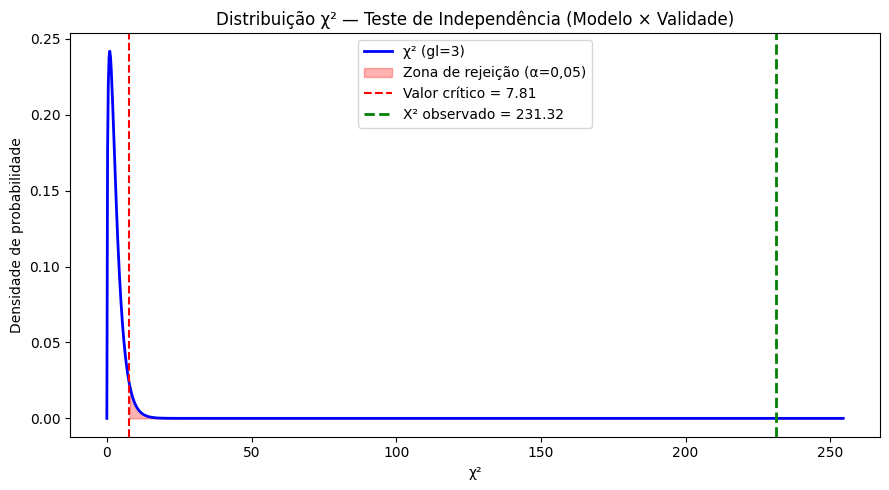

In [18]:
x = np.linspace(0, max(chi2 * 1.1, 30), 1000)
pdf = stats.chi2.pdf(x, dof)
critico = stats.chi2.ppf(0.95, dof)

plt.figure(figsize=(9, 5))
plt.plot(x, pdf, 'b-', lw=2, label=f'χ² (gl={dof})')
plt.fill_between(x, pdf, where=(x >= critico), color='red', alpha=0.3,
                 label='Zona de rejeição (α=0,05)')
plt.axvline(critico, ls='--', color='red', label=f'Valor crítico = {critico:.2f}')
plt.axvline(chi2, ls='--', color='green', lw=2,
            label=f'X² observado = {chi2:.2f}')
plt.xlabel('χ²')
plt.ylabel('Densidade de probabilidade')
plt.title('Distribuição χ² — Teste de Independência (Modelo × Validade)')
plt.legend()
plt.tight_layout()
plt.show()

## Seção 1.3 — Kruskal-Wallis + Dunn's (efeito modelo)

**Kruskal-Wallis:** enfileira todas as réplicas por `taxa_validos`, dá ranks e verifica se os modelos ocupam posições diferentes na fila.
- H0: distribuições iguais. p < 0,05 → há diferença.

**Dunn's (Bonferroni):** identifica quais pares diferem.

In [20]:
grupos = [g['taxa_validos'].values for _, g in df.groupby('modelo')]
H, p = kruskal(*grupos)
print(f"Kruskal-Wallis (efeito modelo): H = {H:.2f}, p = {p:.4g}")

print("\nDunn's post-hoc (Bonferroni) — p-valores:")
dunn = sp.posthoc_dunn(df, val_col='taxa_validos',
                       group_col='modelo', p_adjust='bonferroni')
dunn.round(4)

Kruskal-Wallis (efeito modelo): H = 64.95, p = 5.134e-14

Dunn's post-hoc (Bonferroni) — p-valores:


,Mistral4-119B,Qwen3.6-35B,gemma-4-31B,gpt-oss-120B
Mistral4-119B,1.0000,0.0,0.0415,0.000
Qwen3.6-35B,0.0000,1.0,0.0000,1.000
gemma-4-31B,0.0415,0.0,1.0000,0.002
gpt-oss-120B,0.0000,1.0,0.0020,1.000


## Seção 1.4 — Efeito da Quantização

Três abordagens complementares:
- **1.4a — Teste Z de proporções:** compara Q4 vs BF16 dentro de cada modelo.
- **1.4b — Kruskal-Wallis global:** compara as 4 quantizações ignorando o modelo.
- **1.4c — Kruskal-Wallis por modelo:** compara as 4 quantizações dentro de cada modelo.


### Seção 1.4a — Teste Z de proporções (Q4 vs BF16 por modelo)

Comparação direta da proporção de SMILES válidos entre a quantização mais agressiva (Q4) e a de referência (BF16), dentro de cada modelo.
- H0: proporções iguais.
- p < 0,05 → a quantização Q4 impacta significativamente a validade dentro daquele modelo.

In [23]:
print("Teste Z de proporções — Q4 vs BF16 (por modelo):\n")
for modelo in sorted(df['modelo'].unique()):
    sub_q4   = df[(df['modelo']==modelo) & (df['quantizacao']=='Q4')]
    sub_bf16 = df[(df['modelo']==modelo) & (df['quantizacao']=='BF16')]

    validos = np.array([sub_q4['total_smiles_validos'].sum(),
                        sub_bf16['total_smiles_validos'].sum()])
    total   = np.array([sub_q4['total_smiles'].sum(),
                        sub_bf16['total_smiles'].sum()])

    z, p = proportions_ztest(validos, total)
    prop_q4   = validos[0]/total[0]
    prop_bf16 = validos[1]/total[1]
    print(f"{modelo:20s}: p(Q4)={prop_q4:.3f}  p(BF16)={prop_bf16:.3f}  "
          f"z={z:+.3f}  p={p:.4g}")

Teste Z de proporções — Q4 vs BF16 (por modelo):

Mistral4-119B       : p(Q4)=0.698  p(BF16)=0.865  z=-5.803  p=6.5e-09
Qwen3.6-35B         : p(Q4)=0.942  p(BF16)=0.960  z=-1.362  p=0.1733
gemma-4-31B         : p(Q4)=0.928  p(BF16)=0.892  z=+1.989  p=0.0467
gpt-oss-120B        : p(Q4)=0.974  p(BF16)=0.936  z=+2.898  p=0.003752


### Seção 1.4b — Kruskal-Wallis global (quantização)

Compara a distribuição de `taxa_validos` entre as 4 quantizações, ignorando o modelo.
- H0: distribuições iguais entre BF16, Q4, Q6, Q8.

In [24]:
grupos_q = [g['taxa_validos'].values for _, g in df.groupby('quantizacao')]
H, p = kruskal(*grupos_q)
print(f"Kruskal-Wallis (quantização global): H = {H:.2f}, p = {p:.4g}")

Kruskal-Wallis (quantização global): H = 2.18, p = 0.5363


### Seção 1.4c — Kruskal-Wallis dentro de cada modelo

Testa se a quantização afeta a validade **dentro de cada modelo separadamente**. Detecta efeitos específicos que a análise global pode esconder.

In [25]:
print("Kruskal-Wallis DENTRO de cada modelo:")
for modelo in sorted(df['modelo'].unique()):
    sub = df[df['modelo'] == modelo]
    grupos_m = [g['taxa_validos'].values for _, g in sub.groupby('quantizacao')]
    H, p = kruskal(*grupos_m)
    signif = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "n.s."))
    print(f"  {modelo:20s}: H = {H:6.2f}, p = {p:.4g}  {signif}")

Kruskal-Wallis DENTRO de cada modelo:
  Mistral4-119B       : H =   7.67, p = 0.05346  n.s.
  Qwen3.6-35B         : H =   3.88, p = 0.2743  n.s.
  gemma-4-31B         : H =   5.05, p = 0.1684  n.s.
  gpt-oss-120B        : H =   6.52, p = 0.08894  n.s.


In [26]:
# Dunn's post-hoc por quantização, dentro de cada modelo
for modelo in sorted(df['modelo'].unique()):
    sub = df[df['modelo'] == modelo]
    print(f"\n--- Dunn's post-hoc para {modelo} ---")
    dunn_q = sp.posthoc_dunn(sub, val_col='taxa_validos',
                             group_col='quantizacao', p_adjust='bonferroni')
    print(dunn_q.round(4))


--- Dunn's post-hoc para Mistral4-119B ---
        BF16      Q4      Q6      Q8
BF16  1.0000  0.6583  1.0000  1.0000
Q4    0.6583  1.0000  0.4273  0.0384
Q6    1.0000  0.4273  1.0000  1.0000
Q8    1.0000  0.0384  1.0000  1.0000

--- Dunn's post-hoc para Qwen3.6-35B ---
      BF16      Q4      Q6      Q8
BF16   1.0  1.0000  1.0000  1.0000
Q4     1.0  1.0000  0.7754  1.0000
Q6     1.0  0.7754  1.0000  0.3923
Q8     1.0  1.0000  0.3923  1.0000

--- Dunn's post-hoc para gemma-4-31B ---
        BF16      Q4      Q6      Q8
BF16  1.0000  0.3308  1.0000  1.0000
Q4    0.3308  1.0000  0.3705  0.5534
Q6    1.0000  0.3705  1.0000  1.0000
Q8    1.0000  0.5534  1.0000  1.0000

--- Dunn's post-hoc para gpt-oss-120B ---
        BF16      Q4   Q6      Q8
BF16  1.0000  0.2026  1.0  1.0000
Q4    0.2026  1.0000  1.0  0.1987
Q6    1.0000  1.0000  1.0  1.0000
Q8    1.0000  0.1987  1.0  1.0000


## Seção 1.5a — Two-way ANOVA (tokens/s)

Testa se `modelo` e `quantizacao` afetam a **velocidade de geração** (tokens/s).
- H0 (para cada fator): não há efeito. p < 0,05 → há efeito.

In [27]:
ols_model = smf.ols('token_per_second_medio ~ C(modelo) + C(quantizacao)',
                    data=df).fit()
anova_tbl = anova_lm(ols_model, typ=2)
print("Two-way ANOVA — token_per_second_medio:")
print(anova_tbl.round(4))

Two-way ANOVA — token_per_second_medio:
                     sum_sq     df         F  PR(>F)
C(modelo)       250961.5768    3.0  454.1362     0.0
C(quantizacao)   69434.4724    3.0  125.6476     0.0
Residual         69997.6453  380.0       NaN     NaN


## Seção 1.5c — Teste de Friedman (tempo de resposta)

Alternativa não-paramétrica ao ANOVA de medidas repetidas. Compara o **tempo médio (min)** entre modelos, tratando cada quantização como um "bloco".
- H0: os modelos têm o mesmo tempo. p < 0,05 → há diferença.

In [22]:
matriz_tempo = df.pivot_table(
    index='quantizacao', columns='modelo',
    values='duration_min_media', aggfunc='mean'
)
matriz_tempo = matriz_tempo.fillna(matriz_tempo.mean())
print("Matriz de tempo médio (min) — quantização × modelo:")
print(matriz_tempo.round(3))

stat_f, p_f = stats.friedmanchisquare(*[matriz_tempo[c].values for c in matriz_tempo.columns])
print(f"\nFriedman: X² = {stat_f:.4f}, p = {p_f:.4g}")

Matriz de tempo médio (min) — quantização × modelo:
modelo       Mistral4-119B  Qwen3.6-35B  gemma-4-31B  gpt-oss-120B
quantizacao                                                       
BF16                13.765        8.674       36.372         9.852
Q4                   3.329        1.062        1.499        17.786
Q6                   5.793        1.118        1.958         8.234
Q8                   7.699        1.534        1.631        12.457

Friedman: X² = 8.4000, p = 0.03843


## Seção 1.5d — Correlações (validade × velocidade / tempo)

- **Ponto-bisserial:** correlaciona nº absoluto de SMILES válidos com tokens/s no nível da réplica.
- **Spearman agregado:** médias por grupo (modelo × quantização) — tokens/s vs taxa média e duração vs taxa média.

In [23]:
# Ponto-bisserial
r_pb, p_pb = pointbiserialr(df['total_smiles_validos'],
                            df['token_per_second_medio'])
print(f"Ponto-bisserial (válidos abs × tokens/s): r = {r_pb:.4f}, p = {p_pb:.4g}")

# Agregado por grupo
agg = df.groupby(['modelo','quantizacao']).agg(
    taxa_media=('taxa_validos','mean'),
    tps_medio=('token_per_second_medio','mean'),
    duracao_media=('duration_min_media','mean')
).reset_index()

rho1, p1 = spearmanr(agg['tps_medio'], agg['taxa_media'])
rho2, p2 = spearmanr(agg['duracao_media'], agg['taxa_media'])
print(f"\nSpearman (tokens/s × taxa_media) por grupo: ρ = {rho1:.4f}, p = {p1:.4g}")
print(f"Spearman (duração × taxa_media) por grupo:  ρ = {rho2:.4f}, p = {p2:.4g}")

Ponto-bisserial (válidos abs × tokens/s): r = 0.2063, p = 3.215e-05

Spearman (tokens/s × taxa_media) por grupo: ρ = 0.5611, p = 0.02373
Spearman (duração × taxa_media) por grupo:  ρ = -0.1399, p = 0.6053


## Heatmap — Modelo × Quantização (% válidos médio)

Visualização rápida da taxa média de validade por combinação. Verde = alto, vermelho = baixo.

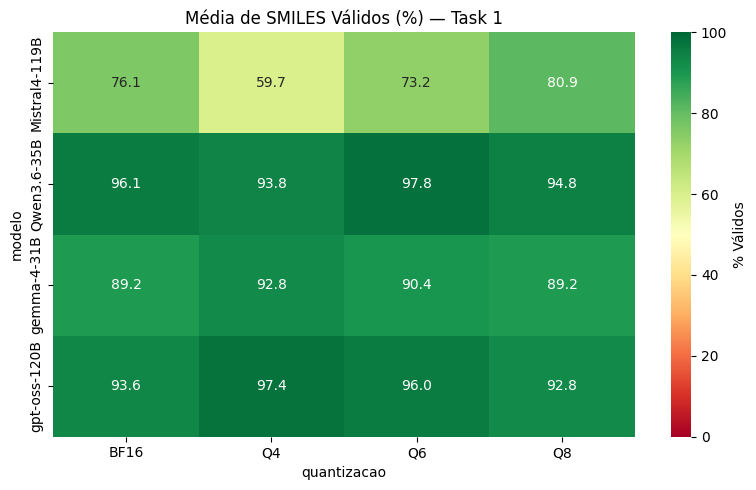

In [24]:
pivot = df.pivot_table(values='pct_validos',
                       index='modelo', columns='quantizacao',
                       aggfunc='mean')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='RdYlGn',
            vmin=0, vmax=100, cbar_kws={'label': '% Válidos'})
plt.title('Média de SMILES Válidos (%) — Task 1')
plt.tight_layout()
plt.show()

## Seção 1.6 — Torneio dos Campeões

Selecionamos manualmente a **melhor configuração** de cada modelo (baseado na análise descritiva prévia) e comparamos as 4 finalistas em um "torneio" via Kruskal-Wallis + Dunn's.

**Finalistas fixadas (Task 1):**
- Qwen3.6-35B (Q6)
- gpt-oss-120B (Q4)
- gemma-4-31B (Q4)
- Mistral4-119B (Q6)

In [25]:
cond = (
    ((df['modelo'] == 'Qwen3.6-35B')   & (df['quantizacao'] == 'Q6')) |
    ((df['modelo'] == 'gpt-oss-120B')  & (df['quantizacao'] == 'Q4')) |
    ((df['modelo'] == 'gemma-4-31B')   & (df['quantizacao'] == 'Q4')) |
    ((df['modelo'] == 'Mistral4-119B') & (df['quantizacao'] == 'Q6'))
)
df_torneio = df[cond].copy()
df_torneio['config'] = df_torneio['modelo'] + ' (' + df_torneio['quantizacao'] + ')'

print("Configurações finalistas:")
print(df_torneio['config'].unique())

desc_torneio = df_torneio.groupby('config')['total_smiles_validos'].agg(
    n='count', mediana='median', media='mean', desvio_padrao='std'
).round(4).sort_values('mediana', ascending=False)
print("\nTabela descritiva das finalistas:")
print(desc_torneio)

Configurações finalistas:
['Qwen3.6-35B (Q6)' 'gemma-4-31B (Q4)' 'gpt-oss-120B (Q4)'
 'Mistral4-119B (Q6)']

Tabela descritiva das finalistas:
                     n  mediana  media  desvio_padrao
config                                               
Qwen3.6-35B (Q6)    25     20.0  19.56         0.7118
gpt-oss-120B (Q4)   25     20.0  19.48         0.5859
gemma-4-31B (Q4)    25     19.0  18.56         2.0224
Mistral4-119B (Q6)  25     17.0  14.52         6.7337


In [26]:
grupos_torneio = [g['taxa_validos'].values for _, g in df_torneio.groupby('config')]
H, p = kruskal(*grupos_torneio)
print(f"Kruskal-Wallis (torneio): H = {H:.2f}, p = {p:.4g}")

print("\nDunn's post-hoc (Bonferroni):")
dunn_torneio = sp.posthoc_dunn(df_torneio, val_col='taxa_validos',
                               group_col='config', p_adjust='bonferroni')
dunn_torneio.round(4)

Kruskal-Wallis (torneio): H = nan, p = nan

Dunn's post-hoc (Bonferroni):


,Mistral4-119B (Q6),Qwen3.6-35B (Q6),gemma-4-31B (Q4),gpt-oss-120B (Q4)
Mistral4-119B (Q6),1.0000,0.0001,0.0987,0.0009
Qwen3.6-35B (Q6),0.0001,1.0000,0.2773,1.0000
gemma-4-31B (Q4),0.0987,0.2773,1.0000,0.8576
gpt-oss-120B (Q4),0.0009,1.0000,0.8576,1.0000


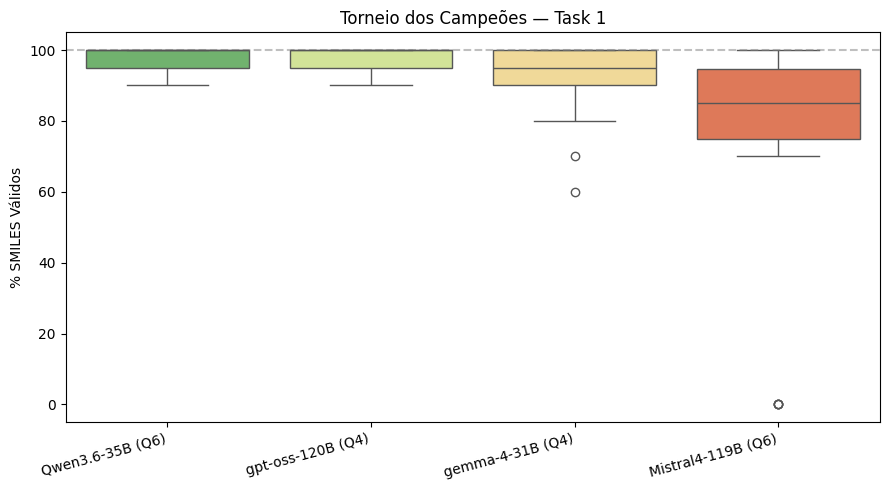

In [27]:
plt.figure(figsize=(9, 5))
ordem = desc_torneio.index.tolist()
sns.boxplot(data=df_torneio, x='config', y='pct_validos', order=ordem,
            palette='RdYlGn_r')
plt.xticks(rotation=15, ha='right')
plt.ylabel('% SMILES Válidos')
plt.xlabel('')
plt.title('Torneio dos Campeões — Task 1')
plt.axhline(100, ls='--', color='gray', alpha=0.5)
plt.tight_layout()
plt.show()

### Conclusões esperadas (Task 1)

1. **Modelo é o preditor dominante** da validade (Qui-quadrado global altamente significativo).
2. **Qwen3.6-35B e gpt-oss-120B** ocupam o topo do ranking, com desempenho estatisticamente equivalente entre si ("empate técnico").
3. **gemma-4-31B** aparece em nível intermediário, consistente porém abaixo dos líderes.
4. **Mistral4-119B** é o pior desempenho global, com maior sensibilidade à quantização Q4.
5. **Quantização** exerce efeito secundário e não uniforme entre modelos.
6. **Velocidade e validade** têm correlação positiva fraca-a-moderada.


# TASK 2

**Objetivo:** Aplicar o mesmo pipeline estatístico da Task 1 aos resultados da Task 2, adicionando testes específicos para lidar com o fato de que `total_smiles` agora varia entre réplicas.

## Estrutura
- Seção 0 — Setup
- **NOVO — Taxa de falha** (réplicas com 0 SMILES)
- Estatística descritiva (geral + por modelo)
- Seção 1.1 — Normalidade + Homocedasticidade
- Seção 1.2 — Qui-quadrado + visualização
- Seção 1.3 — Kruskal-Wallis + Dunn's
- Seção 1.4a — Kruskal-Wallis (quantização)
- Seção 1.4b — Teste Z de proporções
- Seção 1.4c — GLM Quasi-Binomial (com interação)
- **NOVO — Comparação Kruskal × GLM**
- Seção 1.5 — ANOVA + Friedman + correlações
- Heatmap
- Seção 1.6 — Torneio dos Campeões


## Seção 0 — Setup

In [28]:
# Carregar dados da Task 2
df = pd.read_csv("results_task_2.csv")

df['total_smiles_invalidos'] = df['total_smiles'] - df['total_smiles_validos']
df['taxa_validos'] = df['pct_validos'] / 100.0
df['grupo'] = df['modelo'] + "_" + df['quantizacao']

print(f"Total de réplicas: {len(df)}")
print(f"Modelos: {sorted(df['modelo'].unique())}")
print(f"Quantizações: {sorted(df['quantizacao'].unique())}")
print("\nN por combinação modelo × quantização:")
print(df.groupby(['modelo','quantizacao']).size().unstack(fill_value=0))
df.head()

Total de réplicas: 400
Modelos: ['Mistral4-119B', 'Qwen3.6-35B', 'gemma-4-31B', 'gpt-oss-120B']
Quantizações: ['BF16', 'Q4', 'Q6', 'Q8']

N por combinação modelo × quantização:
quantizacao    BF16  Q4  Q6  Q8
modelo                         
Mistral4-119B    25  25  25  25
Qwen3.6-35B      25  25  25  25
gemma-4-31B      25  25  25  25
gpt-oss-120B     25  25  25  25


,task,modelo,quantizacao,replica,total_smiles,total_smiles_validos,total_smiles_duplicados,pct_validos,pct_invalidos,duration_min_media,token_per_second_medio,total_smiles_invalidos,taxa_validos,grupo
0,task_2,gemma-4-31B,Q8,gemma-4-31B-Q8_replica_8,20,20,0,100.0,0.0,3.006838,25.388720,0,1.00,gemma-4-31B_Q8
1,task_2,gemma-4-31B,Q8,gemma-4-31B-Q8_replica_10,20,20,0,100.0,0.0,3.006838,25.388720,0,1.00,gemma-4-31B_Q8
2,task_2,Qwen3.6-35B,Q6,Qwen3.6-35B-Q6_replica_11,20,7,0,35.0,65.0,1.777562,98.259126,13,0.35,Qwen3.6-35B_Q6
3,task_2,gemma-4-31B,Q4,gemma-4-31B-Q4_replica_24,20,20,0,100.0,0.0,2.495117,33.456646,0,1.00,gemma-4-31B_Q4
4,task_2,gpt-oss-120B,BF16,gpt-oss-120B-BF16_replica_6,20,16,0,80.0,20.0,25.854410,14.021201,4,0.80,gpt-oss-120B_BF16


## NOVO — Taxa de falha

Réplicas com `total_smiles == 0` significam **falha total de geração**. Reportamos essa taxa separadamente e removemos essas réplicas das análises de validade (o denominador do GLM binomial ficaria zero).

**Como interpretar:** taxa de falha alta = modelo instável, não confiável para pipeline de produção.

In [29]:
df['falha'] = (df['total_smiles'] == 0).astype(int)

print("Taxa de falha por MODELO (%):")
print((df.groupby('modelo')['falha'].mean() * 100).round(2))

print("\nTaxa de falha por QUANTIZAÇÃO (%):")
print((df.groupby('quantizacao')['falha'].mean() * 100).round(2))

print("\nTaxa de falha por MODELO × QUANTIZAÇÃO (%):")
print((df.groupby(['modelo','quantizacao'])['falha'].mean() * 100)
      .round(2).unstack(fill_value=0))

df_clean = df[df['total_smiles'] > 0].copy()
print(f"\nRéplicas mantidas para análise: {len(df_clean)} de {len(df)}")

Taxa de falha por MODELO (%):
modelo
Mistral4-119B    8.0
Qwen3.6-35B      0.0
gemma-4-31B      0.0
gpt-oss-120B     2.0
Name: falha, dtype: float64

Taxa de falha por QUANTIZAÇÃO (%):
quantizacao
BF16    2.0
Q4      4.0
Q6      3.0
Q8      1.0
Name: falha, dtype: float64

Taxa de falha por MODELO × QUANTIZAÇÃO (%):
quantizacao    BF16   Q4    Q6   Q8
modelo                             
Mistral4-119B   8.0  8.0  12.0  4.0
Qwen3.6-35B     0.0  0.0   0.0  0.0
gemma-4-31B     0.0  0.0   0.0  0.0
gpt-oss-120B    0.0  8.0   0.0  0.0

Réplicas mantidas para análise: 390 de 400


## Estatística descritiva geral (modelo × quantização)

In [30]:
desc = df_clean.groupby(['modelo','quantizacao'])['taxa_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)
desc['CV(%)'] = (desc['desvio_padrao'] / desc['media'] * 100).round(2)
desc

n   media  mediana  desvio_padrao     IQR  minimo  maximo  CV(%)
modelo        quantizacao                                                                   
Mistral4-119B BF16         23  0.6698   0.7895         0.2846  0.3592  0.1500    1.00  42.49
              Q4           23  0.4289   0.4643         0.2866  0.3885  0.0000    1.00  66.82
              Q6           22  0.4909   0.5000         0.2657  0.4255  0.0000    0.95  54.13
              Q8           24  0.6461   0.7381         0.3126  0.4743  0.0357    1.00  48.38
Qwen3.6-35B   BF16         25  0.8200   0.8000         0.1291  0.1000  0.3500    1.00  15.74
              Q4           25  0.7613   0.8500         0.2313  0.3500  0.1500    1.00  30.38
              Q6           25  0.6820   0.8000         0.2951  0.3500  0.0000    1.00  43.27
              Q8           25  0.8200   0.8500         0.1658  0.2000  0.2500    1.00  20.22
gemma-4-31B   BF16         25  0.9380   0.9500         0.0833  0.1000  0.6500    1.00   8.88
              Q4           25  0.9440   0.9500         0.0601  0.1000  0.7500    1.00   6.37
              Q6           25  0.9580   1.0000         0.0589  0.0500  0.8000    1.00   6.15
              Q8           25  0.9220   0.9500         0.1081  0.1000  0.5500    1.00  11.72
gpt-oss-120B  BF16         25  0.8700   0.9000         0.1041  0.1000  0.6000    1.00  11.97
              Q4           23  0.8522   0.8500         0.0923  0.1500  0.7000    1.00  10.83
              Q6           25  0.8880   0.9000         0.0893  0.1000  0.6500    1.00  10.06
              Q8           25  0.8580   0.8500         0.1222  0.1500  0.5000    1.00  14.24

## Estatística descritiva individual por modelo

In [31]:
# --- gemma-4-31B ---
sub = df_clean[df_clean['modelo'] == 'gemma-4-31B']
print("Estatística descritiva — gemma-4-31B")
sub.groupby('quantizacao')['total_smiles_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)

Estatística descritiva — gemma-4-31B


,n,media,mediana,desvio_padrao,IQR,minimo,maximo
quantizacao,,,,,,,
BF16,25,18.76,19.0,1.6653,2.0,13,20
Q4,25,18.88,19.0,1.2014,2.0,15,20
Q6,25,19.16,20.0,1.1790,1.0,16,20
Q8,25,18.44,19.0,2.1618,2.0,11,20


In [32]:
# --- Qwen3.6-35B ---
sub = df_clean[df_clean['modelo'] == 'Qwen3.6-35B']
print("Estatística descritiva — Qwen3.6-35B")
sub.groupby('quantizacao')['total_smiles_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)

Estatística descritiva — Qwen3.6-35B


,n,media,mediana,desvio_padrao,IQR,minimo,maximo
quantizacao,,,,,,,
BF16,25,16.40,16.0,2.5820,2.0,7,20
Q4,25,15.28,17.0,4.6145,7.0,3,20
Q6,25,13.64,16.0,5.9011,7.0,0,20
Q8,25,16.40,17.0,3.3166,4.0,5,20


In [33]:
# --- gpt-oss-120B ---
sub = df_clean[df_clean['modelo'] == 'gpt-oss-120B']
print("Estatística descritiva — gpt-oss-120B")
sub.groupby('quantizacao')['total_smiles_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)

Estatística descritiva — gpt-oss-120B


,n,media,mediana,desvio_padrao,IQR,minimo,maximo
quantizacao,,,,,,,
BF16,25,17.4000,18.0,2.0817,2.0,12,20
Q4,23,17.0435,17.0,1.8458,3.0,14,20
Q6,25,17.7600,18.0,1.7861,2.0,13,20
Q8,25,17.1600,17.0,2.4440,3.0,10,20


In [34]:
# --- Mistral4-119B ---
sub = df_clean[df_clean['modelo'] == 'Mistral4-119B']
print("Estatística descritiva — Mistral4-119B")
sub.groupby('quantizacao')['total_smiles_validos'].agg(
    n='count', media='mean', mediana='median', desvio_padrao='std',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    minimo='min', maximo='max'
).round(4)

Estatística descritiva — Mistral4-119B


,n,media,mediana,desvio_padrao,IQR,minimo,maximo
quantizacao,,,,,,,
BF16,23,13.4348,15.0,5.5418,6.0,3,21
Q4,23,8.0870,7.0,6.3954,11.0,0,19
Q6,22,10.2727,10.0,4.8421,7.0,0,19
Q8,24,12.7500,14.5,8.3471,11.5,1,30


## Seção 1.1 — Normalidade (Shapiro-Wilk) e Homocedasticidade (Levene)

**Shapiro-Wilk:** testa se cada grupo segue distribuição normal.  
- H0: dados normais. p < 0,05 → não-normal.

**Levene (Brown-Forsythe, centro na mediana):** testa se as variâncias são iguais entre grupos.  
- H0: variâncias iguais. p < 0,05 → heterocedástico.

In [35]:
sw_results = []
for grupo, sub in df_clean.groupby('grupo'):
    if len(sub) >= 3:
        W, p = stats.shapiro(sub['taxa_validos'])
        sw_results.append({'grupo': grupo, 'n': len(sub),
                           'W': round(W, 4), 'p': p,
                           'Normal?': 'Sim' if p > 0.05 else 'Não'})
sw_df = pd.DataFrame(sw_results).sort_values('p')
print("Shapiro-Wilk por grupo (modelo_quantizacao):")
print(sw_df.to_string(index=False))
print(f"\nGrupos não-normais: {(sw_df['Normal?']=='Não').sum()} de {len(sw_df)}")

Shapiro-Wilk por grupo (modelo_quantizacao):
             grupo  n      W        p Normal?
    gemma-4-31B_Q8 25 0.7129 0.000011     Não
    gemma-4-31B_Q6 25 0.7446 0.000031     Não
  gemma-4-31B_BF16 25 0.7453 0.000032     Não
    gemma-4-31B_Q4 25 0.8119 0.000362     Não
  Qwen3.6-35B_BF16 25 0.8195 0.000489     Não
 gpt-oss-120B_BF16 25 0.8270 0.000664     Não
    Qwen3.6-35B_Q8 25 0.8394 0.001117     Não
   gpt-oss-120B_Q8 25 0.8819 0.007562     Não
    Qwen3.6-35B_Q6 25 0.8822 0.007673     Não
Mistral4-119B_BF16 23 0.8767 0.008640     Não
    Qwen3.6-35B_Q4 25 0.8856 0.009043     Não
  Mistral4-119B_Q8 24 0.8928 0.015198     Não
   gpt-oss-120B_Q6 25 0.9239 0.063032     Sim
   gpt-oss-120B_Q4 23 0.9421 0.199488     Sim
  Mistral4-119B_Q4 23 0.9421 0.199745     Sim
  Mistral4-119B_Q6 22 0.9666 0.633116     Sim

Grupos não-normais: 12 de 16


In [36]:
grupos_valores = [g['taxa_validos'].values for _, g in df_clean.groupby('grupo')]
stat_lev, p_lev = stats.levene(*grupos_valores, center='median')
print(f"Levene (Brown-Forsythe) global: W = {stat_lev:.4f}, p = {p_lev:.4g}")
print("Homocedasticidade:", "Sim" if p_lev > 0.05 else "Não (heterocedástico)")

Levene (Brown-Forsythe) global: W = 8.8212, p = 1.608e-17
Homocedasticidade: Não (heterocedástico)


## Seção 1.2 — Qui-quadrado de Independência (efeito modelo)

Tabela de contingência (linhas = modelos, colunas = [válidos, inválidos]). Testa se a proporção de válidos depende do modelo.
- H0: modelo e validade são independentes.
- p < 0,05 → modelo influencia a validade.

**Vantagem:** usa contagens absolutas → não sofre com `total_smiles` variável.

In [37]:
tabela = df_clean.groupby('modelo')[['total_smiles_validos','total_smiles_invalidos']].sum()
print("Tabela de contingência (soma por modelo):")
print(tabela)

chi2, p, dof, expected = stats.chi2_contingency(tabela.values)
print(f"\nQui-quadrado global: X² = {chi2:.2f}, gl = {dof}, p = {p:.4g}")

Tabela de contingência (soma por modelo):
               total_smiles_validos  total_smiles_invalidos
modelo                                                     
Mistral4-119B                  1027                     887
Qwen3.6-35B                    1543                     459
gemma-4-31B                    1881                     119
gpt-oss-120B                   1700                     260

Qui-quadrado global: X² = 1052.65, gl = 3, p = 6.804e-228


In [38]:
modelos = sorted(df_clean['modelo'].unique())
pares = list(combinations(modelos, 2))
m = len(pares)

pw_chi = []
for a, b in pares:
    sub = tabela.loc[[a, b]]
    c2, pv, gl, _ = stats.chi2_contingency(sub.values)
    pw_chi.append({'par': f"{a} vs {b}", 'X2': round(c2, 2),
                   'p_bruto': pv, 'p_Bonferroni': min(pv * m, 1.0)})
pd.DataFrame(pw_chi).sort_values('p_Bonferroni')

,par,X2,p_bruto,p_Bonferroni
1,Mistral4-119B vs gemma-4-31B,833.50,2.806695e-183,1.684017e-182
2,Mistral4-119B vs gpt-oss-120B,506.78,3.189724e-112,1.913834e-111
0,Mistral4-119B vs Qwen3.6-35B,236.80,1.958667e-53,1.175200e-52
3,Qwen3.6-35B vs gemma-4-31B,231.99,2.191526e-52,1.314916e-51
4,Qwen3.6-35B vs gpt-oss-120B,61.59,4.226210e-15,2.535726e-14
5,gemma-4-31B vs gpt-oss-120B,60.36,7.880535e-15,4.728321e-14


### Visualização da distribuição χ²
Curva teórica com valor crítico (α = 0,05) e o X² observado marcado.

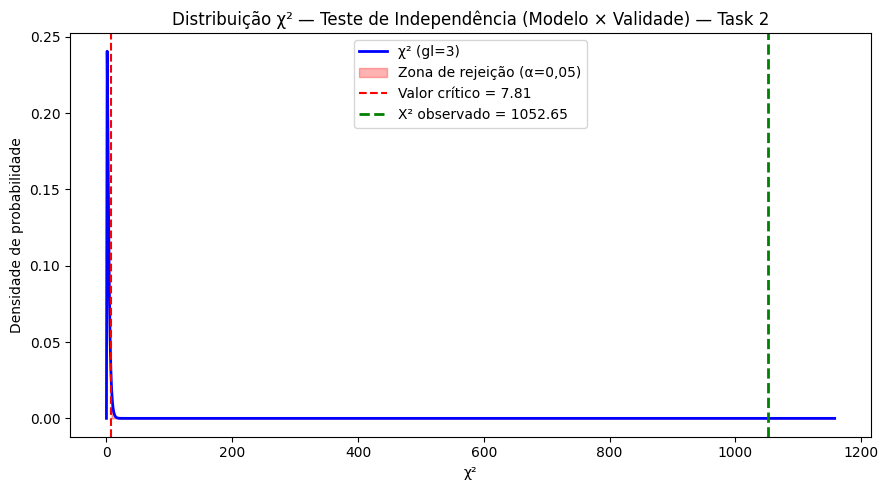

In [39]:
x = np.linspace(0, max(chi2 * 1.1, 30), 1000)
pdf = stats.chi2.pdf(x, dof)
critico = stats.chi2.ppf(0.95, dof)

plt.figure(figsize=(9, 5))
plt.plot(x, pdf, 'b-', lw=2, label=f'χ² (gl={dof})')
plt.fill_between(x, pdf, where=(x >= critico), color='red', alpha=0.3,
                 label='Zona de rejeição (α=0,05)')
plt.axvline(critico, ls='--', color='red', label=f'Valor crítico = {critico:.2f}')
plt.axvline(chi2, ls='--', color='green', lw=2,
            label=f'X² observado = {chi2:.2f}')
plt.xlabel('χ²')
plt.ylabel('Densidade de probabilidade')
plt.title('Distribuição χ² — Teste de Independência (Modelo × Validade) — Task 2')
plt.legend()
plt.tight_layout()
plt.show()

## Seção 1.3 — Kruskal-Wallis + Dunn's (efeito modelo)

**Kruskal-Wallis:** enfileira todas as réplicas por `taxa_validos`, dá ranks e verifica se os modelos ocupam posições diferentes na fila.
- H0: distribuições iguais. p < 0,05 → há diferença.

**Dunn's (Bonferroni):** identifica quais pares diferem.

In [40]:
grupos = [g['taxa_validos'].values for _, g in df_clean.groupby('modelo')]
H, p = stats.kruskal(*grupos)
print(f"Kruskal-Wallis (efeito modelo): H = {H:.2f}, p = {p:.4g}")

print("\nDunn's post-hoc (Bonferroni) — p-valores:")
dunn = sp.posthoc_dunn(df_clean, val_col='taxa_validos',
                       group_col='modelo', p_adjust='bonferroni')
dunn.round(4)

Kruskal-Wallis (efeito modelo): H = 128.42, p = 1.184e-27

Dunn's post-hoc (Bonferroni) — p-valores:


,Mistral4-119B,Qwen3.6-35B,gemma-4-31B,gpt-oss-120B
Mistral4-119B,1.0000,0.0001,0.0,0.0000
Qwen3.6-35B,0.0001,1.0000,0.0,0.1128
gemma-4-31B,0.0000,0.0000,1.0,0.0000
gpt-oss-120B,0.0000,0.1128,0.0,1.0000


## Seção 1.4a — Kruskal-Wallis (efeito quantização)

1. **Marginal (global):** joga tudo no bolo. Pode não detectar efeito se ele depender do modelo (interação).
2. **Estratificado por modelo:** roda Kruskal entre as 4 quantizações **dentro de cada modelo**. Detecta efeitos específicos.

In [41]:
grupos_q = [g['taxa_validos'].values for _, g in df_clean.groupby('quantizacao')]
H, p = stats.kruskal(*grupos_q)
print(f"Kruskal-Wallis MARGINAL (quantização): H = {H:.2f}, p = {p:.4g}")

print("\nKruskal-Wallis DENTRO de cada modelo:")
for modelo in sorted(df_clean['modelo'].unique()):
    sub = df_clean[df_clean['modelo'] == modelo]
    grupos_m = [g['taxa_validos'].values for _, g in sub.groupby('quantizacao')]
    H, p = stats.kruskal(*grupos_m)
    signif = "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else "n.s."))
    print(f"  {modelo:20s}: H = {H:6.2f}, p = {p:.4g}  {signif}")

Kruskal-Wallis MARGINAL (quantização): H = 2.15, p = 0.5428

Kruskal-Wallis DENTRO de cada modelo:
  Mistral4-119B       : H =  11.04, p = 0.01152  *
  Qwen3.6-35B         : H =   2.23, p = 0.5269  n.s.
  gemma-4-31B         : H =   1.88, p = 0.597  n.s.
  gpt-oss-120B        : H =   1.89, p = 0.5946  n.s.


In [42]:
for modelo in sorted(df_clean['modelo'].unique()):
    sub = df_clean[df_clean['modelo'] == modelo]
    print(f"\n--- Dunn's post-hoc para {modelo} ---")
    dunn_q = sp.posthoc_dunn(sub, val_col='taxa_validos',
                             group_col='quantizacao', p_adjust='bonferroni')
    print(dunn_q.round(4))


--- Dunn's post-hoc para Mistral4-119B ---
        BF16      Q4      Q6      Q8
BF16  1.0000  0.0368  0.2461  1.0000
Q4    0.0368  1.0000  1.0000  0.0659
Q6    0.2461  1.0000  1.0000  0.3937
Q8    1.0000  0.0659  0.3937  1.0000

--- Dunn's post-hoc para Qwen3.6-35B ---
      BF16   Q4      Q6      Q8
BF16   1.0  1.0  1.0000  1.0000
Q4     1.0  1.0  1.0000  1.0000
Q6     1.0  1.0  1.0000  0.9619
Q8     1.0  1.0  0.9619  1.0000

--- Dunn's post-hoc para gemma-4-31B ---
      BF16   Q4   Q6   Q8
BF16   1.0  1.0  1.0  1.0
Q4     1.0  1.0  1.0  1.0
Q6     1.0  1.0  1.0  1.0
Q8     1.0  1.0  1.0  1.0

--- Dunn's post-hoc para gpt-oss-120B ---
      BF16   Q4   Q6   Q8
BF16   1.0  1.0  1.0  1.0
Q4     1.0  1.0  1.0  1.0
Q6     1.0  1.0  1.0  1.0
Q8     1.0  1.0  1.0  1.0


## Seção 1.4b — Teste Z de proporções (Q4 vs BF16 por modelo)

Comparação direta da proporção de SMILES válidos entre Q4 e BF16, dentro de cada modelo.
- H0: proporções iguais.
- p < 0,05 → quantização Q4 impacta significativamente a validade dentro daquele modelo.

In [43]:
print("Teste Z de proporções — Q4 vs BF16 (por modelo):\n")
for modelo in sorted(df_clean['modelo'].unique()):
    sub_q4   = df_clean[(df_clean['modelo']==modelo) & (df_clean['quantizacao']=='Q4')]
    sub_bf16 = df_clean[(df_clean['modelo']==modelo) & (df_clean['quantizacao']=='BF16')]

    validos = np.array([sub_q4['total_smiles_validos'].sum(),
                        sub_bf16['total_smiles_validos'].sum()])
    total   = np.array([sub_q4['total_smiles'].sum(),
                        sub_bf16['total_smiles'].sum()])

    z, p = proportions_ztest(validos, total)
    prop_q4   = validos[0]/total[0]
    prop_bf16 = validos[1]/total[1]
    print(f"{modelo:20s}: p(Q4)={prop_q4:.3f}  p(BF16)={prop_bf16:.3f}  "
          f"z={z:+.3f}  p={p:.4g}")

Teste Z de proporções — Q4 vs BF16 (por modelo):

Mistral4-119B       : p(Q4)=0.388  p(BF16)=0.663  z=-8.456  p=2.772e-17
Qwen3.6-35B         : p(Q4)=0.761  p(BF16)=0.820  z=-2.296  p=0.02168
gemma-4-31B         : p(Q4)=0.944  p(BF16)=0.938  z=+0.403  p=0.6872
gpt-oss-120B        : p(Q4)=0.852  p(BF16)=0.870  z=-0.799  p=0.4245


## Seção 1.4c — GLM Quasi-Binomial (com interação)

Trata cada SMILES gerado como uma tentativa Bernoulli (válido = 1, inválido = 0). Modela:

$$\text{logit}(p) = \beta_0 + \beta_{\text{modelo}} + \beta_{\text{quant}} + \beta_{\text{modelo × quant}}$$

**Por que quasi-binomial?** Se a dispersão de Pearson > 1, há **superdispersão** (variância maior que o binomial assume). O ajuste `scale='X2'` corrige os erros-padrão.

**Como interpretar coeficientes (logits) → odds ratios:**
- OR = exp(coef). OR = 2 → chance 2x maior de gerar SMILES válido.

In [44]:
model = smf.glm(
    formula='total_smiles_validos + total_smiles_invalidos ~ C(modelo) * C(quantizacao)',
    data=df_clean,
    family=sm.families.Binomial()
).fit()

pearson_disp = model.pearson_chi2 / model.df_resid
print(f"Dispersão de Pearson: {pearson_disp:.3f}")
print("→ Superdispersão detectada" if pearson_disp > 1.5 else "→ Sem superdispersão relevante")

model_q = smf.glm(
    formula='total_smiles_validos + total_smiles_invalidos ~ C(modelo) * C(quantizacao)',
    data=df_clean,
    family=sm.families.Binomial()
).fit(scale='X2')

print(f"\nEscala quasi-binomial: {model_q.scale:.3f}\n")
print(model_q.summary())

Dispersão de Pearson: 3.835
→ Superdispersão detectada

Escala quasi-binomial: 0.199

                                 Generalized Linear Model Regression Results                                  
Dep. Variable:     ['total_smiles_validos', 'total_smiles_invalidos']   No. Observations:                  390
Model:                                                            GLM   Df Residuals:                      374
Model Family:                                                Binomial   Df Model:                           15
Link Function:                                                  Logit   Scale:                         0.19874
Method:                                                          IRLS   Log-Likelihood:                -1204.0
Date:                                                Tue, 07 Jul 2026   Deviance:                       1542.6
Time:                                                        13:42:03   Pearson chi2:                 1.43e+03
No. Iterations:           

In [45]:
def joint_wald(mod, tipo):
    names = mod.model.exog_names
    if tipo == 'modelo':
        idx = [i for i, n in enumerate(names)
               if n.startswith('C(modelo)[T.') and ':' not in n]
    elif tipo == 'quantizacao':
        idx = [i for i, n in enumerate(names)
               if n.startswith('C(quantizacao)[T.') and ':' not in n]
    else:
        idx = [i for i, n in enumerate(names) if ':' in n]
    R = np.zeros((len(idx), len(names)))
    for row, col in enumerate(idx):
        R[row, col] = 1
    wt = mod.wald_test(R, use_f=False)
    return float(wt.statistic), len(idx), float(wt.pvalue)

print("Testes de Wald conjuntos (GLM quasi-binomial):")
for termo in ['modelo', 'quantizacao', 'interacao']:
    chi2v, gl, pv = joint_wald(model_q, termo)
    print(f"  {termo:15s}: X² = {chi2v:8.2f}, gl = {gl}, p = {pv:.4g}")

Testes de Wald conjuntos (GLM quasi-binomial):
  modelo         : X² =   603.82, gl = 3, p = 1.498e-130
  quantizacao    : X² =   460.62, gl = 3, p = 1.63e-99
  interacao      : X² =   358.28, gl = 9, p = 1.069e-71


## NOVO — Comparação Kruskal × GLM

**Divergência esperada** entre os dois métodos para quantização:

| Método | Enxerga efeito de quantização? |
|---|---|
| Kruskal-Wallis marginal | Provavelmente **não** (p > 0,05) |
| GLM quasi-binomial | **Sim** (p muito baixo) |

**Por quê?**
1. **Kruskal marginal** ignora o denominador variável (`total_smiles`) e joga todos os modelos no mesmo bolo. Como o efeito da quantização é **oposto entre modelos** (Mistral colapsa em Q4, gemma é indiferente), os efeitos se cancelam quando marginalizados.
2. **GLM** pesa cada réplica pelo n gerado e modela a **interação** explicitamente. Detecta o efeito.

**Decisão:** confiar no GLM para conclusões sobre quantização. O Kruskal fica como análise auxiliar / continuidade com a Task 1. A **interação significativa** é o achado central.

## Seção 1.5a — Two-way ANOVA (tokens/s)

Testa se `modelo` e `quantizacao` afetam a **velocidade de geração** (tokens/s).
- H0 (para cada fator): não há efeito. p < 0,05 → há efeito.

In [46]:
ols_model = smf.ols('token_per_second_medio ~ C(modelo) + C(quantizacao)',
                    data=df_clean).fit()
anova_tbl = anova_lm(ols_model, typ=2)
print("Two-way ANOVA — token_per_second_medio:")
print(anova_tbl.round(4))

Two-way ANOVA — token_per_second_medio:
                     sum_sq     df         F  PR(>F)
C(modelo)       253777.4855    3.0  460.6197     0.0
C(quantizacao)   65214.3358    3.0  118.3675     0.0
Residual         70337.6877  383.0       NaN     NaN


## Seção 1.5c — Teste de Friedman (tempo de resposta)

Alternativa não-paramétrica ao ANOVA de medidas repetidas. Compara o **tempo médio (min)** entre modelos, tratando cada quantização como um "bloco".
- H0: os modelos têm o mesmo tempo. p < 0,05 → há diferença.

In [48]:
matriz_tempo = df_clean.pivot_table(
    index='quantizacao', columns='modelo',
    values='duration_min_media', aggfunc='mean'
)
matriz_tempo = matriz_tempo.fillna(matriz_tempo.mean())
print("Matriz de tempo médio (min) — quantização × modelo:")
print(matriz_tempo.round(3))

stat_f, p_f = stats.friedmanchisquare(*[matriz_tempo[c].values for c in matriz_tempo.columns])
print(f"\nFriedman: X² = {stat_f:.4f}, p = {p_f:.4g}")

Matriz de tempo médio (min) — quantização × modelo:
modelo       Mistral4-119B  Qwen3.6-35B  gemma-4-31B  gpt-oss-120B
quantizacao                                                       
BF16                10.373        9.716       74.179        25.854
Q4                   2.092        2.047        2.495        38.961
Q6                   4.634        1.778        3.351        20.957
Q8                   5.271        1.936        3.007        21.786

Friedman: X² = 9.3000, p = 0.02556


## Seção 1.5d — Correlações (validade × velocidade / tempo)

- **Ponto-bisserial:** correlaciona nº absoluto de SMILES válidos com tokens/s no nível da réplica.
- **Spearman agregado:** médias por grupo (modelo × quantização) — tokens/s vs taxa média e duração vs taxa média.

In [49]:
r_pb, p_pb = stats.pointbiserialr(df_clean['total_smiles_validos'],
                                  df_clean['token_per_second_medio'])
print(f"Ponto-bisserial (válidos abs × tokens/s): r = {r_pb:.4f}, p = {p_pb:.4g}")

agg = df_clean.groupby(['modelo','quantizacao']).agg(
    taxa_media=('taxa_validos','mean'),
    tps_medio=('token_per_second_medio','mean'),
    duracao_media=('duration_min_media','mean')
).reset_index()

rho1, p1 = stats.spearmanr(agg['tps_medio'], agg['taxa_media'])
rho2, p2 = stats.spearmanr(agg['duracao_media'], agg['taxa_media'])
print(f"\nSpearman (tokens/s × taxa_media) por grupo: ρ = {rho1:.4f}, p = {p1:.4g}")
print(f"Spearman (duração × taxa_media) por grupo:  ρ = {rho2:.4f}, p = {p2:.4g}")

Ponto-bisserial (válidos abs × tokens/s): r = -0.0095, p = 0.8514

Spearman (tokens/s × taxa_media) por grupo: ρ = 0.2237, p = 0.4049
Spearman (duração × taxa_media) por grupo:  ρ = 0.2943, p = 0.2685


## Heatmap — Modelo × Quantização (% válidos médio)

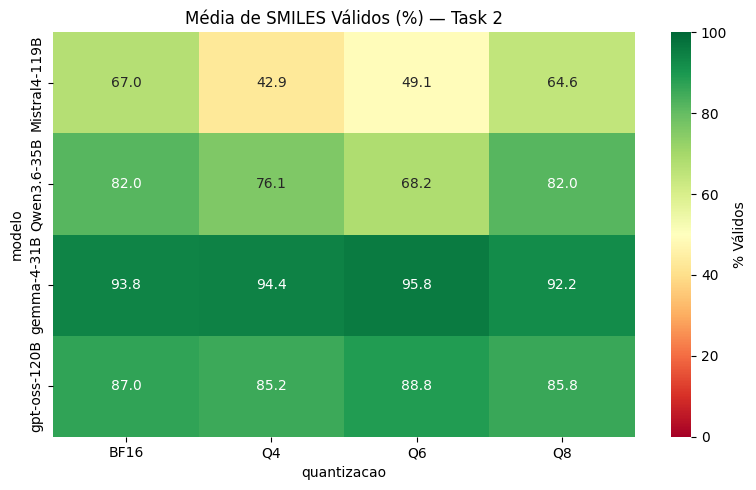

In [50]:
pivot = df_clean.pivot_table(values='pct_validos',
                             index='modelo', columns='quantizacao',
                             aggfunc='mean')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='RdYlGn',
            vmin=0, vmax=100, cbar_kws={'label': '% Válidos'})
plt.title('Média de SMILES Válidos (%) — Task 2')
plt.tight_layout()
plt.show()

## Seção 1.6 — Torneio dos Campeões

Seleciona automaticamente a **melhor quantização de cada modelo** (por mediana de `taxa_validos`) e compara as 4 configurações finalistas via Kruskal + Dunn's.

In [51]:
medianas = (df_clean.groupby(['modelo','quantizacao'])['taxa_validos']
            .median().reset_index())
campeoes = medianas.loc[medianas.groupby('modelo')['taxa_validos'].idxmax()]
print("Configurações campeãs (maior mediana de taxa_validos):")
print(campeoes.to_string(index=False))

mask = False
for _, row in campeoes.iterrows():
    mask = mask | ((df_clean['modelo'] == row['modelo']) &
                   (df_clean['quantizacao'] == row['quantizacao']))
df_torneio = df_clean[mask].copy()
df_torneio['config'] = df_torneio['modelo'] + ' (' + df_torneio['quantizacao'] + ')'

desc_torneio = df_torneio.groupby('config')['total_smiles_validos'].agg(
    n='count', mediana='median', media='mean', desvio_padrao='std'
).round(4).sort_values('mediana', ascending=False)
print("\nTabela descritiva das finalistas:")
print(desc_torneio)

Configurações campeãs (maior mediana de taxa_validos):
       modelo quantizacao  taxa_validos
Mistral4-119B        BF16      0.789474
  Qwen3.6-35B          Q4      0.850000
  gemma-4-31B          Q6      1.000000
 gpt-oss-120B        BF16      0.900000

Tabela descritiva das finalistas:
                       n  mediana    media  desvio_padrao
config                                                   
gemma-4-31B (Q6)      25     20.0  19.1600         1.1790
gpt-oss-120B (BF16)   25     18.0  17.4000         2.0817
Qwen3.6-35B (Q4)      25     17.0  15.2800         4.6145
Mistral4-119B (BF16)  23     15.0  13.4348         5.5418


In [52]:
grupos_torneio = [g['taxa_validos'].values for _, g in df_torneio.groupby('config')]
H, p = stats.kruskal(*grupos_torneio)
print(f"Kruskal-Wallis (torneio): H = {H:.2f}, p = {p:.4g}")

print("\nDunn's post-hoc (Bonferroni):")
dunn_torneio = sp.posthoc_dunn(df_torneio, val_col='taxa_validos',
                               group_col='config', p_adjust='bonferroni')
dunn_torneio.round(4)

Kruskal-Wallis (torneio): H = 29.66, p = 1.626e-06

Dunn's post-hoc (Bonferroni):


,Mistral4-119B (BF16),Qwen3.6-35B (Q4),gemma-4-31B (Q6),gpt-oss-120B (BF16)
Mistral4-119B (BF16),1.0000,0.9647,0.0000,0.1094
Qwen3.6-35B (Q4),0.9647,1.0000,0.0006,1.0000
gemma-4-31B (Q6),0.0000,0.0006,1.0000,0.0208
gpt-oss-120B (BF16),0.1094,1.0000,0.0208,1.0000


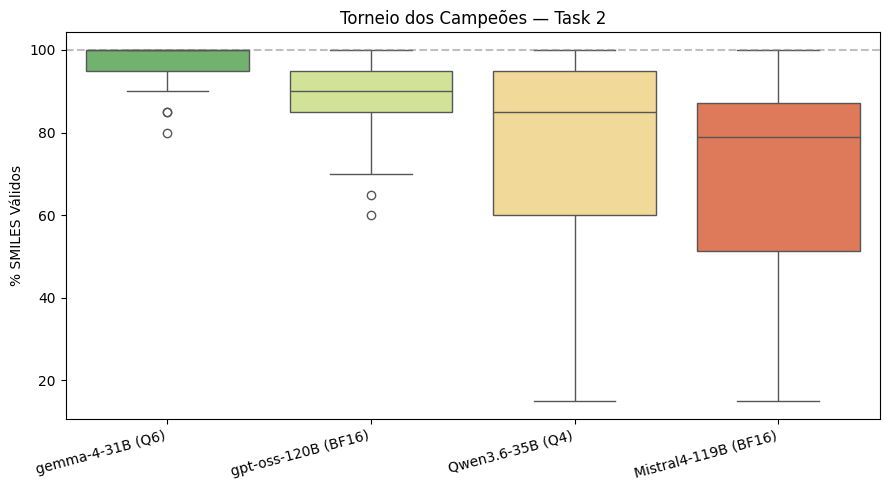

In [53]:
plt.figure(figsize=(9, 5))
ordem = desc_torneio.index.tolist()
sns.boxplot(data=df_torneio, x='config', y='pct_validos', order=ordem,
            palette='RdYlGn_r')
plt.xticks(rotation=15, ha='right')
plt.ylabel('% SMILES Válidos')
plt.xlabel('')
plt.title('Torneio dos Campeões — Task 2')
plt.axhline(100, ls='--', color='gray', alpha=0.5)
plt.tight_layout()
plt.show()

### Conclusões esperadas (Task 2)

1. **Modelo** é o preditor dominante da validade (χ², Kruskal e GLM concordam).
2. **Quantização** só aparece como significativa no **GLM** por causa da interação — o Kruskal marginal a esconde.
3. A **interação modelo × quantização** é o achado mais interessante da Task 2 e deve ser destacada.
4. **Mistral** é o modelo mais instável (maior taxa de falha e maior sensibilidade à quantização).
5. **gemma** é o mais robusto (alta validade e insensível à precisão dos bits).
